In [49]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.formula.api as sm
import scipy.stats as stats
import seaborn as sns

In [50]:
data = pd.read_csv('./Advertising.csv')

data_train = data.sample(frac = 0.8, random_state = 49)
data_test = data.drop(data_train.index)

data_train.head()

,TV,Radio,Newspaper,Sales
107,90.4,0.3,23.2,12.0
144,96.2,14.8,38.9,12.3
104,238.2,34.3,5.3,20.7
195,38.2,3.7,13.8,7.6
153,171.3,39.7,37.7,16.0


<Axes: >

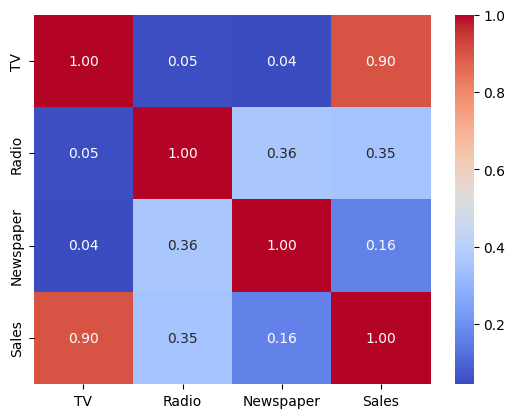

In [51]:
corr = data_train.corr()
sns.heatmap(corr, cmap = 'coolwarm', annot = True, fmt = '.2f')

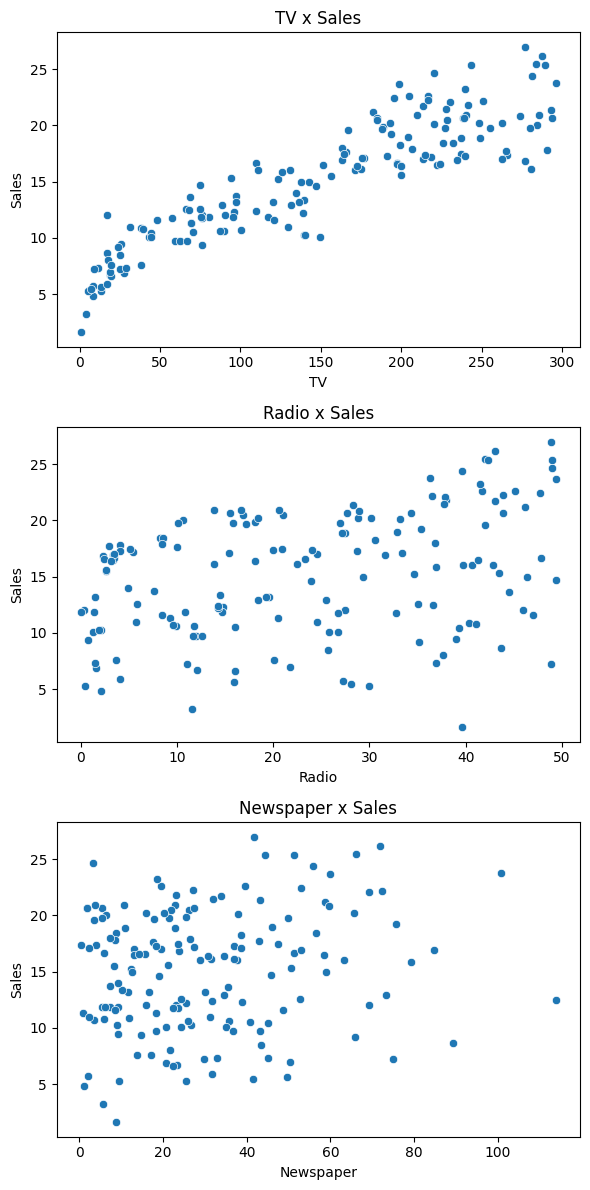

In [52]:
columns_pairs = [
    ('TV', 'Sales'),
    ('Radio', 'Sales'),
    ('Newspaper', 'Sales')
]

n_plot = len(columns_pairs)

fig, axes = plt.subplots(
    nrows = n_plot,
    ncols = 1,
    figsize = (6, 4 * n_plot)
)

for i, pair in enumerate(columns_pairs):
    x_col, y_col = pair
    sns.scatterplot(
        x = x_col,
        y = y_col,
        data = data_train,
        ax = axes[i]
    )

    axes[i].set_title(f'{x_col} x {y_col}')

plt.tight_layout()
plt.show()

In [53]:
formula = 'Sales ~ TV + Radio '

model = sm.ols(formula = formula, data = data_train)

model = model.fit()
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  Sales   R-squared:                       0.903
Model:                            OLS   Adj. R-squared:                  0.902
Method:                 Least Squares   F-statistic:                     729.3
Date:                Fri, 09 Oct 2026   Prob (F-statistic):           3.35e-80
Time:                        17:06:58   Log-Likelihood:                -311.52
No. Observations:                 160   AIC:                             629.0
Df Residuals:                     157   BIC:                             638.3
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      4.5565      0.329     13.840      0.000       3.906       5.207
TV             0.0544      0.002     35.560      0.000       0.051       0.057
Radio          0.1091      0.009     12.141      0.000       0.091       0.127
==============================================================================
Omnibus:                       16.145   Durbin-Watson:                   2.261
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               25.602
Skew:                          -0.535   Prob(JB):                     2.76e-06
Kurtosis:                       4.642   Cond. No.                         421.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

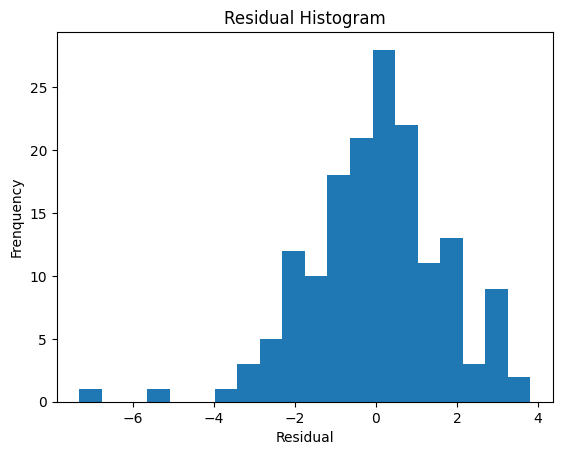

In [54]:
residual = model.resid

plt.hist(residual, bins = 20)
plt.xlabel('Residual')
plt.ylabel('Frenquency')
plt.title('Residual Histogram')
plt.show()

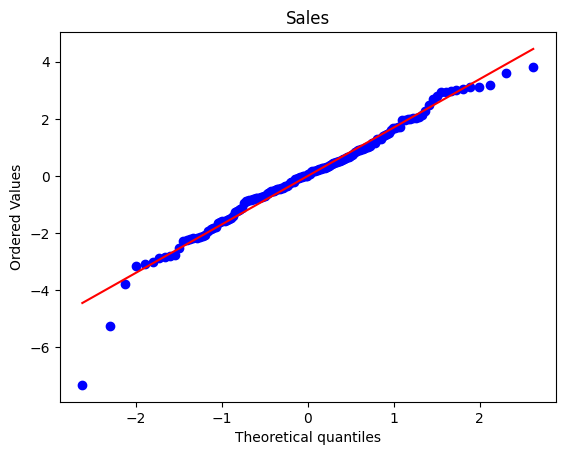

In [55]:
stats.probplot(residual, dist = 'norm', plot = plt)
plt.title('Sales')
plt.show()

In [56]:
shapiro_test = stats.shapiro(residual)
print(f'Shapiro-Wilk test: \nW => {shapiro_test[0]} \nP => {shapiro_test[1]}')

Shapiro-Wilk test: 
W => 0.974442547357383 
P => 0.004592880100948734


In [57]:
prediction = model.predict(data_test)
real = data_test['Sales']

mediun_error = np.mean(np.abs(real - prediction))
mediun_percent = np.mean(np.abs(real - prediction) / real) * 100
rmse_log = np.sqrt(np.mean((np.log(prediction) - np.log(real)) ** 2))
r2 = 1 - np.sum((real - prediction) **2) / np.sum((real - real.mean()) **2)

print(f'Erro médio: {mediun_error}')
print(f'Erro médio percentual: {mediun_percent:.2f}%')
print(f'RMSE (log): {rmse_log:.4f}%')
print(f'R² no teste: {r2:.3f}')

comparation = pd.DataFrame({
    'Real': real,
    'Prediction': prediction,
})

comparation['Diference'] = comparation['Real'] - comparation['Prediction']

comparation['DiferencePercent(%)'] = ((comparation['Prediction'] - comparation['Real']) / comparation['Real']) *100

comparation.head()

Erro médio: 1.0548423959883693
Erro médio percentual: 7.13%
RMSE (log): 0.1017%
R² no teste: 0.901


,Real,Prediction,Diference,DiferencePercent(%)
4,17.9,15.575079,2.324921,-12.988387
20,18.0,19.464828,-1.464828,8.137931
31,11.9,12.599257,-0.699257,5.876108
36,25.4,23.860589,1.539411,-6.060675
40,16.6,18.010452,-1.410452,8.496701
